# 12. Artificial data with the ingredient that makes the autoencoder win

**Round 3 result, first (section 5, added afterwards):** with the schedule-aware simple checks among the rivals, there is no dial setting and no fault size where the autoencoder leads the best simple detector by more than 12 points. A check of the distance to the nearest normal reading catches every faulty reading at every dial and size; the autoencoder is 10 to 90 points behind it.

**Why.** Notebook 11 found what the autoencoder learned on the penicillin batches: the controller outputs step through a fixed recipe, and their joint values sit on a few dozen islands that no straight line passes through. A fault that puts one output between the islands (at a value that is normal on its own) is seen by the autoencoder and missed by straight-line detectors. Notebook 11 ended with a recipe for artificial data with that ingredient. This notebook builds it, with one dial that turns the ingredient from absent to penicillin-like and beyond, and runs a first, small pilot.

**Read this first.** The generator was built to resemble IndPenSim, after seeing what makes the autoencoder win there. So it cannot confirm that win: a generator made in the win's image will tend to reproduce it. Its value is in turning the ingredient up and down and watching what changes. The full sweep, and training on generated data, are a later task.

**The generator** (`simulate.recipe_batches`; fixed before computing, written in `adlab/simulate.py`):

- **Sensors:** 6 controller outputs that step through a fixed recipe over each batch (4 to 7 values each, going up and down, steps at different points of the batch), and 6 measurements.
- **The dial:** each output = its best straight line over the batch + *dial* × (its recipe steps − that line). At dial 0 every output is a straight ramp, so their joint values lie on one line. At dial 1 they sit on the recipe's islands. Above 1 the islands sit further from the line.
- **Measurements:** straight-line mixes, each in its own proportions, of the batch's progress and of lagged responses to two of the outputs (the feed and the air flow). So the only bend in the data is the outputs' islands. Noise of 2% of each measurement's level, and a slow, harmless drift: an offset that wanders from batch to batch.
- **Batches:** the same recipe on each batch's own clock; lengths vary by about 10% (about 250 readings).
- **Faults** (the kind notebook 11 found, in a generic form): one stepped output held, for about 8% of the batch, at a value inside its normal range that it does not take at that time, at least a quarter of its range away from its value then. Half are "between steps" (midway between two of its own values), half "wrong step" (its value at another stage). The measurements respond, through the lags, only when the output held is the feed or the air flow.

**Fixed before computing** (also in `adlab/mechanism.py`):

1. **Check the generator:** the curved share and the kinked share (notebook 08's measure, whole batches held out in five rounds) on 60 normal batches at dial 0, 0.25, 0.5, 0.75, 1, 1.5 and 2. Expected: about zero at dial 0. The *penicillin-like* dial is the one on that grid whose curved share is nearest IndPenSim's (+14.8 points); *the middle* is half of it. Both are chosen on normal data only.
2. **The pilot:** at dial 0, the middle and the penicillin-like dial, detectors fitted on 60 normal batches, one alarm line from 30 other normal batches, scored on 30 faulty batches. Detectors: straight-link, kinked-link, PCA scored like the autoencoder, PCA with corners (the best straight-line ingredient model of notebook 11), and the autoencoder (three seeds). **The question: does the autoencoder's gain over the best of the four simple detectors grow with the dial?** Margin rule and ranges as everywhere else.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
import pandas as pd

from adlab import explore, mechanism, plots, simulate

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", explore.tidy)
pd.set_option("display.max_columns", 30)

## 1. What the generated batches look like

Three outputs and three measurements over four normal batches (blue) and two batches with the feed held (orange), at dial 0 and at dial 1. The x-axis is the reading number.

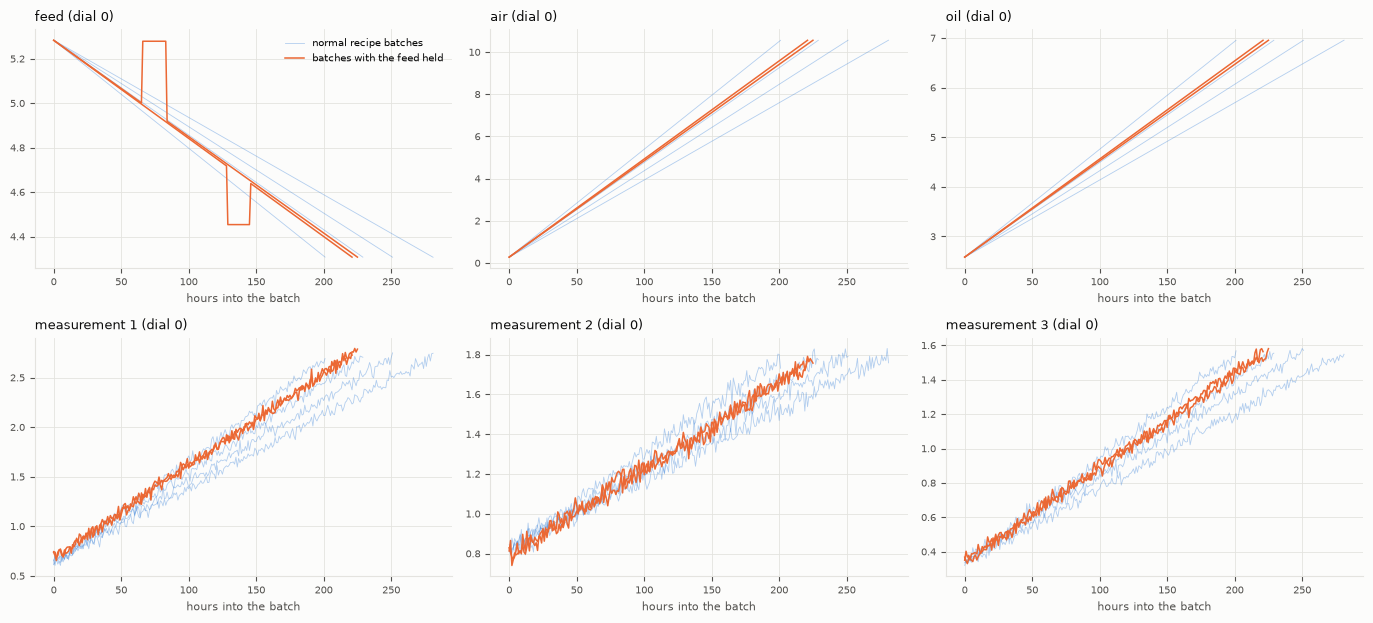

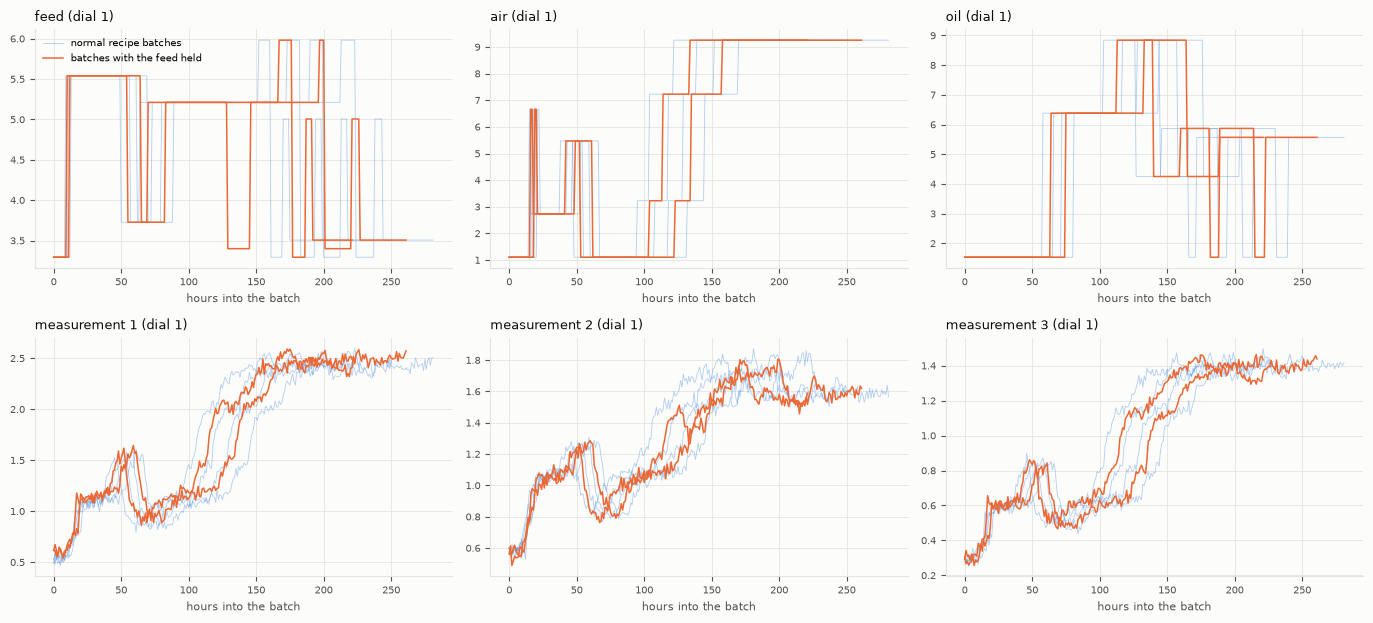

In [2]:
import numpy as np
for dial in (0.0, 1.0):
    normal = simulate.recipe_batches(4, dial=dial, seed=mechanism.SEEDS["fit"])
    faulty = [b for b in simulate.recipe_batches(12, dial=dial, seed=mechanism.SEEDS["faulty"], faulty=True)
              if b["output held"] == "feed"][:2]
    t = lambda b: np.arange(len(b["X"]))
    plots.over_time_with_faults([(t(b), b["X"]) for b in normal], [(t(b), b["X"]) for b in faulty],
                                ["feed", "air", "oil", "measurement 1", "measurement 2", "measurement 3"], mechanism.CHANNELS,
                                {c: f"{c} (dial {dial:g})" for c in mechanism.CHANNELS}, across=3,
                                faulty_names=["batches with the feed held"]);

**What this shows.** At dial 0 every output climbs or falls in a straight line over the batch, and the measurements follow smoothly. At dial 1 the outputs step through the recipe, up and down, each at its own times. When the feed is held, its line goes flat for a stretch, and the measurements bend away from the normal batches with a lag.

## 2. Does the dial turn the curve on and off?

The curved share (how much more a flexible model explains than a straight line, in points, on batches it never saw) and the kinked gain (the same for a straight model allowed corners), at each dial. *Kinked share of the curve* is the kinked gain over the curved share.

In [3]:
curv = mechanism.curvature_table()      # about 20 minutes the first time; then read from results/cache
print("IndPenSim-like dial:", mechanism.indpensim_like(curv), "| pilot dials:", mechanism.pilot_dials())
curv

IndPenSim-like dial: 2.0 | pilot dials: [0.0, 1.0, 2.0]


,"curved share, points",curved range,straight share,"kinked gain, points",kinked share of the curve
dial,,,,,
0,0.002,+0.0 to +0.0,0.996,0,NaN
0.25,3.148,+3.1 to +3.2,0.961,1.728,0.549
0.5,6.434,+6.4 to +6.5,0.925,3.596,0.559
0.75,8.552,+8.5 to +8.6,0.902,5.188,0.607
1,7.919,+7.9 to +8.0,0.886,4.601,0.581
1.5,11.665,+11.6 to +11.7,0.869,7.377,0.632
2,12.481,+12.4 to +12.5,0.861,8.31,0.666


**What this shows.**

- **At dial 0 the curved share is zero** (0.002 points): with every output a straight ramp and the measurements straight mixes, a straight line explains everything a flexible model can.
- **It rises as the dial turns up**, to +12.5 points at dial 2, though not quite steadily: it dips from +8.6 at dial 0.75 to +7.9 at dial 1 (why is not worked out here).
- **Corners recover 55 to 67% of the curve**, as on the real batches: the kinked share is 0.67 at dial 2, against 0.64 on IndPenSim. A straight model allowed a few corners marks out some of the islands, not all.
- **The penicillin-like dial is 2**, by the rule fixed in advance: its curved share (+12.5) is the one on the grid nearest IndPenSim's +14.8, though a little under it. The middle is 1. The ranges here are very narrow, because the generated batches differ much less from one another than real ones.

*Noted after seeing the table:* the grid stopped at 2, so the dial nearest IndPenSim is the grid's last; a dial a little above 2 would match it more closely. The pilot keeps the rule as fixed.

## 3. The pilot: does the autoencoder gain more as the dial turns up?

Catch rate at 1 false alarm in 100 for each detector at each pilot dial, the autoencoder's gap to the best simple detector, its range, and the verdict by the margin rule. Fitting, line and scoring as on the penicillin batches.

In [4]:
for dial in mechanism.pilot_dials():
    mechanism.score(dial)               # about 5 minutes per dial the first time
pilot = mechanism.pilot_table()
pilot

,Straight-link residual,Kinked-link residual,"PCA, scored like the autoencoder",PCA + corners (hinge terms),Autoencoder,best simple,"autoencoder minus best simple, points",range,verdict,spread across seeds
dial,,,,,,,,,,
0,1,1,1,1,1,Straight-link residual,0,+0.0 to +0.0,tie,0
1,0.236,0.34,0.271,0.41,0.799,PCA + corners (hinge terms),38.861,+23.6 to +55.0,ahead,0.041
2,0.113,0.402,0.052,0.139,0.856,Kinked-link residual,45.418,+32.5 to +57.8,ahead,0.044


**What this shows. Yes: the autoencoder's gain over the best simple detector grows with the dial**, from nothing at dial 0 to **+39 points (+24 to +55)** at dial 1 and **+45 (+33 to +58)** at the penicillin-like dial 2, both ahead by the margin.

- **At dial 0 every detector catches every faulty reading.** With every output a straight ramp, a value held off its ramp is plain to a straight model. So dial 0 sits at the ceiling: it says the simple detectors miss nothing when the links are straight, not that the autoencoder gains nothing there in general.
- **Most of the growth is the simple detectors falling.** As the islands appear, the straight-link detector drops from 1.00 to 0.24 to 0.11, and PCA scored like the autoencoder from 1.00 to 0.27 to 0.05. The autoencoder stays at 0.80 to 0.86. Corners help the straight models a little (the kinked-link detector holds at about 0.35 to 0.40) but not enough.
- **From dial 1 to dial 2 the gain grows by 7 points**, well inside the ranges: the pilot shows a clear rise from straight links to islands, not a steady rise beyond that.
- **Both kinds of fault behave alike**: the autoencoder catches 0.66 to 0.89 of "between steps" faults and 0.73 to 0.85 of "wrong step" faults, the simple detectors 0.04 to 0.43.
- **The autoencoder's line carries over:** on the faulty batches' own normal readings it raises false alarms 1.2% and 1.6% of the time (the line is set for 1%).
- The gaps are far larger than on the penicillin batches (+19 there). The generator was built in the win's image, with little noise and batches much alike, so that is expected and says nothing new about the real data.

## 4. What this does and does not show

**It shows** that the ingredient found in notebook 11 is enough, on its own, to give an autoencoder a large lead over straight-line detectors, the kinked one included: controller outputs that step through a recipe, so that their joint values sit on islands, and a fault that puts one output between the islands at a value that is normal on its own. With the ingredient turned off, the straight-line detectors catch everything.

**It does not show** that this is what happens on other plants, or how large the gain would be on real data: the generator was built from the penicillin batches. Nor does it say where between dial 0 and dial 1 the gain appears, or how noise, drift, the number of outputs or the fault size change it.

**Later tasks** (not done here): the full sweep (more dial settings, noise levels and fault sizes, more seeds), and training on generated batches, then testing on the published ones.

## 5. Round 3: a finer dial, three fault sizes, and simple checks that know the schedule

*Added in round 3, after everything above.* Fixed before computing: the pilot rerun at every dial of section 2 (0, 0.25, 0.5, 0.75, 1, 1.5 and 2) and at three fault sizes (as before, half and a quarter: the held value moves that share of the way from the output's scheduled value), with the four schedule-aware checks of notebook 09, section 12 added to the simple detectors. The same faulty batches at every size. For each size: the first dial where the autoencoder's gap over the best simple detector (the checks included) exceeds 12 points.

In [5]:
sweep = mechanism.sweep_table()          # about 25 minutes the first time; then read from results/cache
display(mechanism.crossover(sweep))
names = ["Straight-link residual", "Kinked-link residual", "PCA, scored like the autoencoder", "PCA + corners (hinge terms)",
         "Unseen value check", "Nearest normal reading (k = 1)", "Nearest normal readings (k = 5)", "Recipe at this hour",
         "Autoencoder", "best simple", "gap, points", "range", "verdict"]
sweep[names]

,first dial with a gap over 12 points,gap there,range there,a win by the margin rule
fault size,,,,
1,none,NaN,,False
0.5,none,NaN,,False
0.25,none,NaN,,False


Straight-link residual Kinked-link residual  \
fault size dial                                               
1          0                         1                    1   
           0.25                  0.735                0.904   
           0.5                    0.34                0.777   
           0.75                  0.211                0.595   
           1                     0.236                 0.34   
           1.5                   0.151                0.402   
           2                     0.113                0.402   
0.5        0                         1                    1   
           0.25                  0.186                0.646   
           0.5                   0.024                0.282   
           0.75                  0.002                 0.12   
           1                     0.023                0.104   
           1.5                   0.002                0.127   
           2                     0.002                0.086   
0.25       0                         1                    1   
           0.25                  0.012                0.232   
           0.5                       0                0.098   
           0.75                      0                0.046   
           1                         0                0.064   
           1.5                       0                0.015   
           2                         0                0.019   

                PCA, scored like the autoencoder PCA + corners (hinge terms)  \
fault size dial                                                                
1          0                                   1                           1   
           0.25                             0.68                       0.866   
           0.5                             0.473                       0.428   
           0.75                            0.313                       0.423   
           1                               0.271                        0.41   
           1.5                             0.093                       0.189   
           2                               0.052                       0.139   
0.5        0                                   1                       0.997   
           0.25                            0.167                       0.349   
           0.5                             0.058                       0.014   
           0.75                            0.015                       0.036   
           1                               0.037                       0.156   
           1.5                             0.002                       0.024   
           2                               0.005                       0.027   
0.25       0                               0.979                       0.844   
           0.25                             0.01                       0.024   
           0.5                             0.005                           0   
           0.75                            0.009                           0   
           1                               0.012                        0.06   
           1.5                             0.015                           0   
           2                               0.015                           0   

                Unseen value check Nearest normal reading (k = 1)  \
fault size dial                                                     
1          0                     0                              1   
           0.25                  0                              1   
           0.5                   0                              1   
           0.75                  0                          0.998   
           1                   0.4                              1   
           1.5                   0                              1   
           2                     0                              1   
0.5        0                     0                              1   
           0.25                  0 

**What this shows. There is no such dial, at any fault size.** At every dial above 0, a simple check that knows the schedule beats the autoencoder: the **nearest normal reading** (k = 1 or 5) catches **every** faulty reading at every dial and every size. The autoencoder is 10 to 20 points behind it with faults at full size, 29 to 43 points behind at half size, and 54 to 90 points behind at a quarter. At dial 0 every detector catches (nearly) everything, as before.

- **Why the nearest normal reading is so strong here.** The generator's controller outputs carry no noise: every normal batch's outputs lie exactly on the recipe's path. A held value, however small the shift, is off that path, and the distance to the nearest normal reading shows it at once. The autoencoder, which has to rebuild the readings through a bottleneck, blurs small shifts (0.10 to 0.47 of quarter-size faults).
- **The unseen value check works only at dial 1.** Between dial 0 and 2, each output is a blend of a ramp and the recipe's steps, so it takes hundreds of values and the check (30 values or fewer) watches none of them. At dial 1, the pure steps, it catches 0.4 of full-size faults (half of them are held at a value the output takes at another stage, which this check cannot see by design) and all of the smaller ones, which land between steps.
- **Recipe at this hour does poorly** (0 to 0.12 above dial 0): the generator's recipe runs on each batch's own clock, and batch lengths vary by 10%, so the same reading number is not the same point of the recipe.
- **Straight-line models fall as the dial turns up**, as in section 3; the kinked-link detector holds best of them.

**So the generator, built to resemble the penicillin batches, says the same as the penicillin batches themselves (notebook 09, section 12):** what lets the autoencoder beat straight-line models here, a schedule of controller outputs on islands, is better caught by a simple lookup of normal readings. The autoencoder's advantage over straight lines is real; its advantage over a check that knows the schedule is not.